# 量子化学 · H2 的 RHF、变分能量与 Pauli 测量

QuantumBridge / 科学计算 / 中文可执行案例

**执行状态：仅本地运行；未提交夸父真机；新增云任务 0。**

面向了解 Python 的读者：完成建模、检查中间结果、运行原生电路或明确标记的经典密码步骤，并与独立基线核对。

**范围边界：** 仅 H2 的氢原子 s 基、四模式教学体系；不代表任意元素、激发态、偶极矩或分子结构优化全覆盖。采样能量可能在统计误差内低于精确能量，这不意味着突破变分原理。键长扫描是经典参考，不是真机结构优化。

## 1. 原理与计算对象

从 H-H 核坐标和氢原子 STO-3G 收缩高斯基开始，计算单、双电子积分，RHF 自洽得到轨道，再进行 Jordan-Wigner 映射。电子哈密顿量为
$H=E_{nuc}+\sum h_{pq}a_p^\dagger a_q+\frac12\sum g_{pqrs}a_p^\dagger a_q^\dagger a_s a_r$。
四个自旋轨道映射为四个量子比特，初态 |1100>。原生双激发门产生变分态，最小化 $E(\theta)=\langle\psi(\theta)|H|\psi(\theta)\rangle$。本例用确定性网格及局部细化，优化目标是本地精确态能量，不是带噪真机 VQE。

每个非平凡 Pauli 项独立测量；X 项先 H，Y 项先 S† 再 H。由对应位的奇偶性得到 ±1 样本，最后 $\hat E=E_{const}+\sum c_j\hat P_j$。独立电路的能量标准误为 $\sqrt{\sum c_j^2 SE_j^2}$。核排斥能只计入一次。

## 2. 实现步骤

1. 设置 0.735 Å 键长和 2 个电子，构造本地分子积分与 RHF 历史。
2. 输出全部 Pauli 系数；在固定电子数扇区对角化得到经典精确基线。
3. 搜索双激发角，保存每一步角度与能量；另做键长扫描。
4. 逐项构建测量基变换，输出原生电路的 OpenQASM 2。
5. 每项采样 1024 次，合并能量及标准误，与变分值、RHF、精确值分别比较。

## 3. 环境与可复现参数

依赖本仓库、NumPy、Matplotlib、Jupyter；安全案例还使用已安装的 OpenSSL / cryptography。模型和电路不调用 Qiskit 或 PennyLane。Notebook 保留真实执行输出，Python 解释器版本会在下方打印。

In [1]:
import os, sys, json
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
root = next((p for p in [Path(os.environ.get("QB_REPO_ROOT", ".")).resolve(), *Path.cwd().resolve().parents] if (p/"quantumbridge").is_dir() and (p/"scripts").is_dir()), None)
if root is None:
    raise RuntimeError("Run from the QuantumBridge checkout or set QB_REPO_ROOT.")
sys.path.insert(0, str(root)); sys.path.insert(0, str(root/"scripts"))
from IPython.display import display, HTML
from application_notebook_support import STYLE, show_json, intermediate_tables, plot_intermediate, show_measurements
from quantumbridge.applications.common import run_local_case
display(HTML(STYLE))
SHOTS, SEED = 1024, 20261023
print("Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit:", SHOTS)

print(sys.version)
import numpy as np
from quantumbridge.core import Circuit
from quantumbridge.devices import StatevectorDevice
from quantumbridge.chemistry import Molecule, molecular_hamiltonian_native
from quantumbridge.chemistry.excitations import apply_fermionic_excitation
from quantumbridge.chemistry.fermion import FermionicOp
from quantumbridge.chemistry.mappings import JordanWignerMapper
from quantumbridge.finance.kernels import labels, prepare_real_state
from quantumbridge.utils.math import PauliString
from quantumbridge.applications.common import ApplicationCase, optimization_case

Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit: 1024
3.12.6 (v3.12.6:a4a2d2b0d85, Sep  6 2024, 16:08:03) [Clang 13.0.0 (clang-1300.0.29.30)]


## 4. 完整应用建模代码

以下是本案例实际执行的应用函数，不是伪代码。底层电路、映射、演化与采样复用仓库原生接口；优化类的共享辅助函数也位于 `quantumbridge/applications/common.py`。

In [2]:
def chemistry_case():
    """Geometry-derived H2/STO-3G, RHF, a real variational circuit and Pauli sampling."""
    problem = molecular_hamiltonian_native(
        Molecule(["H", "H"], [(0, 0, 0), (0, 0, 0.735)])
    )
    matrix = problem.hamiltonian.matrix()
    device = StatevectorDevice()

    def ansatz(theta):
        circuit = Circuit(4, name="h2-double-excitation").x(0).x(1)
        return apply_fermionic_excitation(circuit, theta, (0, 1, 2, 3))

    trace = []
    for theta in np.linspace(-0.6, 0.6, 61):
        vector = device.statevector(ansatz(theta))
        trace.append(
            {
                "theta": float(theta),
                "energy_hartree": float(np.vdot(vector, matrix @ vector).real),
            }
        )
    best = min(trace, key=lambda row: row["energy_hartree"])
    center = best["theta"]
    for theta in np.linspace(center - 0.02, center + 0.02, 41):
        vector = device.statevector(ansatz(theta))
        trace.append(
            {
                "theta": float(theta),
                "energy_hartree": float(np.vdot(vector, matrix @ vector).real),
            }
        )
    best = min(trace, key=lambda row: row["energy_hartree"])
    state = ansatz(best["theta"])
    circuits, estimands, coefficients, constant, table = {}, {}, {}, 0.0, []
    for coefficient, pauli in problem.hamiltonian.terms:
        label = "".join(dict(pauli.terms).get(q, "I") for q in range(4))
        table.append({"pauli": label, "coefficient_hartree": float(coefficient)})
        if not pauli.terms:
            constant += coefficient
            continue
        probe = state.copy()
        for wire, axis in pauli.terms:
            if axis == "X":
                probe.h(wire)
            elif axis == "Y":
                probe.phase(-np.pi / 2, wire)
                probe.h(wire)
        circuits[label] = probe
        estimands[label] = [
            (-1.0) ** sum(int(bits[wire]) for wire, axis in pauli.terms)
            for bits in labels(4)
        ]
        coefficients[label] = float(coefficient)
    scan = []
    for distance in (0.5, 0.65, 0.735, 0.9, 1.2):
        other = molecular_hamiltonian_native(
            Molecule(["H", "H"], [(0, 0, 0), (0, 0, distance)])
        )
        scan.append(
            {
                "distance_angstrom": distance,
                "rhf_hartree": other.scf_result.total_energy,
                "exact_sector_hartree": other.exact_ground_energy(),
            }
        )
    return ApplicationCase(
        "chemistry",
        "science",
        "H2: geometry, RHF, variational energy and Pauli measurements",
        {
            "geometry_angstrom": [[0, 0, 0], [0, 0, 0.735]],
            "basis": "hydrogen STO-3G s-shells",
            "electrons": 2,
            "qubits": 4,
            "units": "Hartree; nuclear repulsion included once",
        },
        {
            "scf_history": list(problem.scf_result.history),
            "pauli_terms": table,
            "variational_trace": trace,
            "bond_scan": scan,
        },
        {
            "exact_ground_energy_hartree": problem.exact_ground_energy(),
            "rhf_energy_hartree": problem.scf_result.total_energy,
        },
        circuits,
        estimands,
        {
            "optimized_theta": best["theta"],
            "variational_energy_hartree": best["energy_hartree"],
            "variational_gap_hartree": best["energy_hartree"]
            - problem.exact_ground_energy(),
            "pauli_energy_constant": float(constant),
            "pauli_energy_terms": coefficients,
        },
    )


In [3]:
case = chemistry_case()
show_json(case.inputs)

## 5. 中间结果与效果

下方完整列出模型候选、优化轨迹或物理中间量。图中的 exact / classical 是经典计算基线，不冒充量子实验。图表使用英文坐标避免本机中文字体缺失，解释与表格保留中文。

iteration,total_energy,density_change,commutator_residual
1,-1.116999,1.2025404,1.5700925e-16
2,-1.116999,0,1.5700925e-16


pauli,coefficient_hartree
IIII,-0.090578994
ZIII,0.17218393
IZII,0.17218393
ZZII,0.16892754
IIZI,-0.22575349
ZIZI,0.12091263
IIIZ,-0.22575349
ZIIZ,0.16614543
IZZI,0.16614543
IZIZ,0.12091263


theta,energy_hartree
-0.6,-1.0801494
-0.58,-1.0859984
-0.56,-1.0915413
-0.54,-1.0967762
-0.52,-1.1017007
-0.5,-1.1063131
-0.48,-1.1106114
-0.46,-1.1145939
-0.44,-1.118259
-0.42,-1.1216053


distance_angstrom,rhf_hartree,exact_sector_hartree
0.5,-1.0429963,-1.0551598
0.65,-1.1129965,-1.1299048
0.735,-1.116999,-1.137306
0.9,-1.091914,-1.1205603
1.2,-1.0051067,-1.0567407


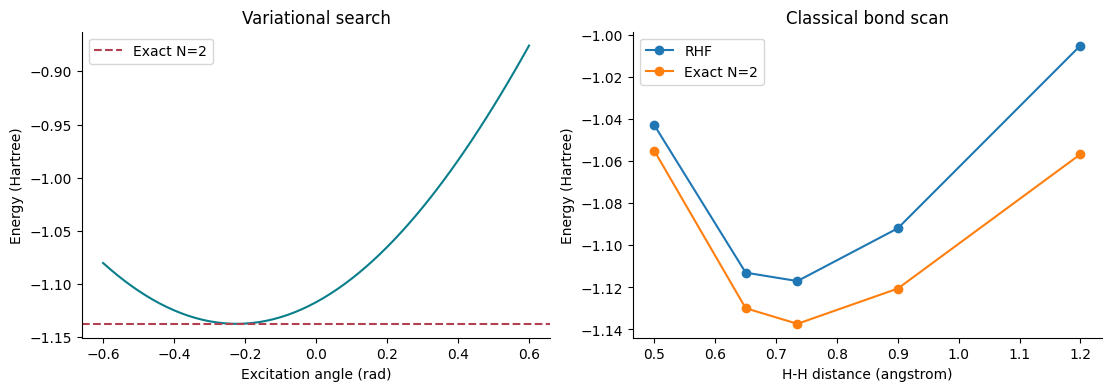

In [4]:
intermediate_tables(case)
plot_intermediate(case)

## 6. 实际运行与最终效果

模拟器使用固定种子逐次采样，counts 总数必须等于 shots。估计标准误由实际样本方差计算；近似 95% 区间可写作 estimate ± 1.96 × SE，但小样本及零计数需另用适当区间。本例不把这些区间当成硬件精度验收。

experiment,qubits,gates,shots,seed
ZIII,4,154,1024,20261023
IZII,4,154,1024,20261024
ZZII,4,154,1024,20261025
IIZI,4,154,1024,20261026
ZIZI,4,154,1024,20261027
IIIZ,4,154,1024,20261028
ZIIZ,4,154,1024,20261029
IZZI,4,154,1024,20261030
IZIZ,4,154,1024,20261031
YXXY,4,160,1024,20261032


observable,estimate,standard_error,ideal_reference
ZIII,-0.9765625,0.0067293498,-0.97501673
IZII,-0.96679688,0.0079897174,-0.97501673
ZZII,1,0,1
IIZI,0.9765625,0.0067293498,0.97501673
ZIZI,-1,0,-1
IIIZ,0.97070312,0.0075124818,0.97501673
ZIIZ,-1,0,-1
IZZI,-1,0,-1
IZIZ,-1,0,-1
YXXY,-0.22851562,0.030437999,-0.22213146


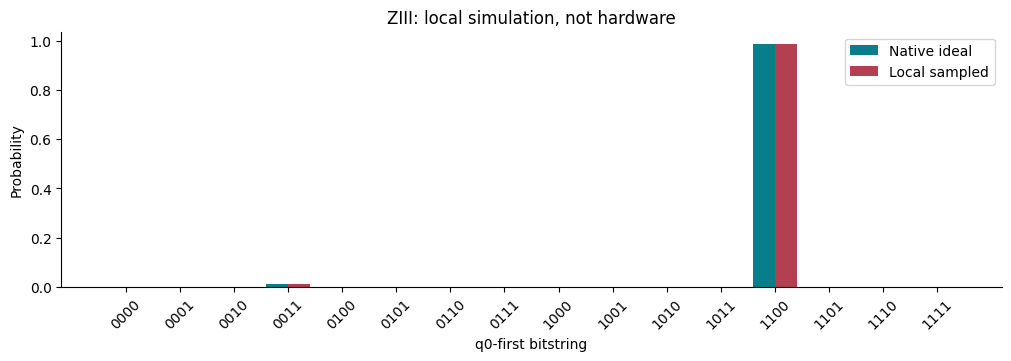

experiment,counts
ZIII,"{""1100"": 1012, ""0011"": 12}"
IZII,"{""1100"": 1007, ""0011"": 17}"
ZZII,"{""1100"": 1014, ""0011"": 10}"
IIZI,"{""1100"": 1012, ""0011"": 12}"
ZIZI,"{""1100"": 1010, ""0011"": 14}"
IIIZ,"{""1100"": 1009, ""0011"": 15}"
ZIIZ,"{""1100"": 1011, ""0011"": 13}"
IZZI,"{""1100"": 1019, ""0011"": 5}"
IZIZ,"{""1100"": 1013, ""0011"": 11}"
YXXY,"{""1110"": 75, ""1001"": 40, ""0111"": 69, ""0110"": 48, ""1100"": 52, ""1000"": 82, ""1011"": 83, ""1101"": 90, ""0011"": 66, ""0000"": 57, ""0010"": 79, ""1010"": 43, ""0001"": 82, ""1111"": 41, ""0100"": 69, ""0101"": 48}"


In [5]:
evidence = run_local_case(case, shots=SHOTS, seed=SEED)
show_measurements(case, evidence)

## 7. 可检查的电路输出

导出全部业务电路的 OpenQASM 2，位串采用 q0-first。可导出不等于已通过夸父设备门集、耦合图、深度和精度验收；本批不会访问凭据、提交任务或消耗金融额度。纯经典案例没有伪造量子电路。

In [6]:
for name, result in evidence['experiments'].items():
    print('\n---', name, '---\n'+result['openqasm2'])
if not evidence['experiments']:
    print('Classical cryptography / security workflow: no quantum circuit.')


--- ZIII ---
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[4];
x q[0];
x q[1];
h q[0];
h q[1];
u1(-1.5707963267948966) q[2];
h q[2];
h q[3];
cx q[0],q[1];
cx q[1],q[2];
cx q[2],q[3];
rz(-0.027999999999999997) q[3];
cx q[2],q[3];
cx q[1],q[2];
cx q[0],q[1];
h q[3];
h q[2];
u1(1.5707963267948966) q[2];
h q[1];
h q[0];
u1(-1.5707963267948966) q[0];
h q[0];
u1(-1.5707963267948966) q[1];
h q[1];
u1(-1.5707963267948966) q[2];
h q[2];
h q[3];
cx q[0],q[1];
cx q[1],q[2];
cx q[2],q[3];
rz(0.027999999999999997) q[3];
cx q[2],q[3];
cx q[1],q[2];
cx q[0],q[1];
h q[3];
h q[2];
u1(1.5707963267948966) q[2];
h q[1];
u1(1.5707963267948966) q[1];
h q[0];
u1(1.5707963267948966) q[0];
u1(-1.5707963267948966) q[0];
h q[0];
h q[1];
u1(-1.5707963267948966) q[2];
h q[2];
u1(-1.5707963267948966) q[3];
h q[3];
cx q[0],q[1];
cx q[1],q[2];
cx q[2],q[3];
rz(-0.027999999999999997) q[3];
cx q[2],q[3];
cx q[1],q[2];
cx q[0],q[1];
h q[3];
u1(1.5707963267948966) q[3];
h q[2];
u1(1.5707963267948966) q[2];
h q[1

## 8. 结果解释、复做与非目标

变分误差和采样误差是两个不同指标。先看 variational_gap_hartree，再看 sampled_energy_hartree 及 energy_standard_error_hartree；14 个测量电路均为本地模拟。

仅 H2 的氢原子 s 基、四模式教学体系；不代表任意元素、激发态、偶极矩或分子结构优化全覆盖。采样能量可能在统计误差内低于精确能量，这不意味着突破变分原理。键长扫描是经典参考，不是真机结构优化。

练习：对已有电路将 shots 改为 2048，比较估计与标准误；如果是纯经典密码案例，比较密文/公钥大小和篡改检测结果。安全案例的私钥只在临时目录或内存中存在，不输出密钥。重新执行此 Notebook 仍然只运行本地代码。

In [7]:
repeat = run_local_case(case, shots=2048, seed=SEED+100)
show_json({'execution_mode':repeat['execution_mode'], 'estimates':repeat['estimates'], 'new_cloud_tasks':repeat['new_cloud_tasks']})
assert all(sum(row['counts'].values()) == 2048 for row in repeat['experiments'].values())
assert repeat['new_cloud_tasks'] == 0
assert repeat['hardware_access'] is False

In [8]:
artifact = {'inputs':case.inputs, 'intermediate':case.intermediate, 'reference':case.reference, 'evidence':evidence}
path = root/'output/jupyter-notebook/science/01_chemistry_evidence.json'
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(artifact, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidence:', path.name)

Evidence: 01_chemistry_evidence.json


## 9. 参考与责任边界

独立编写应用代码，未复制上游 SDK 实现或第三方教程代码；下列资料用于数学与接口背景。

- [PennyLane 分子量子化学概念](https://docs.pennylane.ai/en/stable/introduction/chemistry.html)

本案例不是生产支持证书，也不代表 Qiskit / PennyLane 全量替代已经完成。